In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

Question 1 - Part 1.1:
Random Deposition - (1D & without any relaxation)

In [2]:
#Random Deposition
@njit
def RD(N, L):
    
   h = np.zeros(L)
   h_mean = np.empty(N)
   w = np.empty(N)

   for t in range(N):
     
     i = np.random.randint(L)
     h[i] += 1
     h_mean[t] = np.mean(h)
     w[t] = np.sqrt(np.sum((h - h_mean[t])**2)/L)

   return w

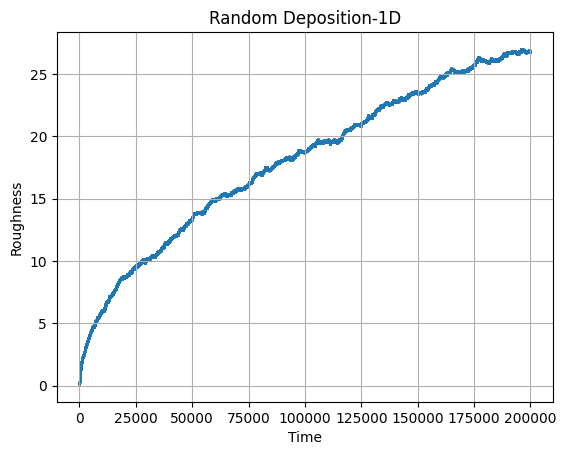

In [3]:
N = 200000
L = 256
w = RD(N, L)

plt.scatter(range(N), w, marker='.', s=1)

plt.xlabel("Time")
plt.ylabel("Roughness")
plt.title("Random Deposition-1D")

plt.grid(True)
plt.show()

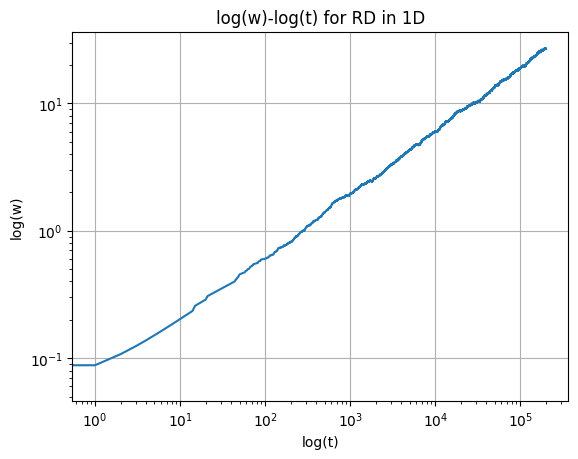

In [4]:
#x = np.linspace(1, 20000, 20000)
#y = np.power(x, 2)

plt.figure()
plt.loglog(range(N), w)
plt.xlabel("log(t)")
plt.ylabel("log(w)")
plt.title("log(w)-log(t) for RD in 1D")

plt.grid(True)
plt.show()

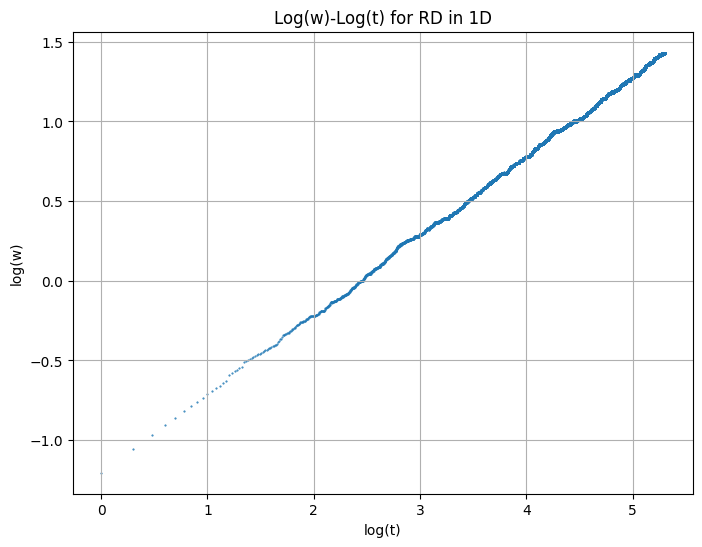

In [5]:
log_w = np.log10(w)
log_t = np.log10(np.arange(1, N+1))

plt.figure(figsize=(8, 6))
plt.scatter(log_t, log_w, marker='.', s=1)
plt.xlabel("log(t)")
plt.ylabel("log(w)")
plt.title("Log(w)-Log(t) for RD in 1D")

plt.grid(True)
plt.show()

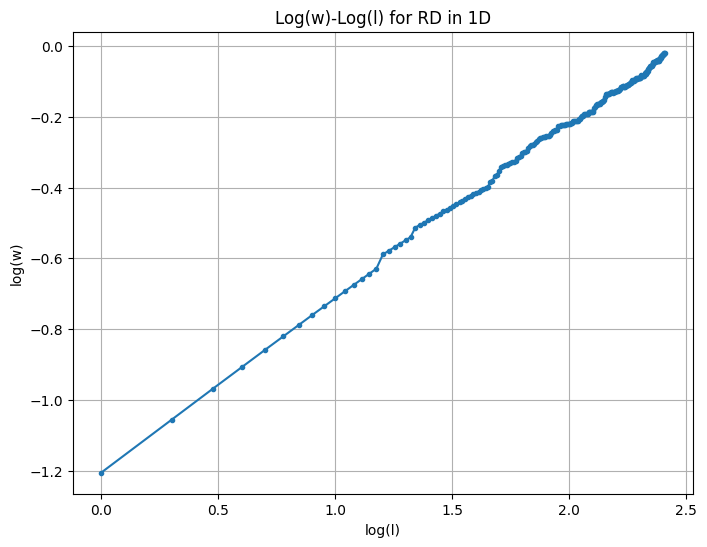

In [6]:
log_w = np.log10(w)
log_l = np.log10(np.arange(1, L+1))

#x_new
log_l_new = log_l
#y_new
log_w_new = log_w[:len(log_l)]

plt.figure(figsize=(8, 6))
plt.plot(log_l_new, log_w_new, marker='.')
plt.xlabel("log(l)")
plt.ylabel("log(w)")
plt.title("Log(w)-Log(l) for RD in 1D")

plt.grid(True)
plt.show()


In [7]:
coeffs_beta = np.polyfit(log_t, log_w, 1)
beta = coeffs_beta[0]

coeffs_alpha = np.polyfit(log_l_new, log_w_new, 1)
alpha = coeffs_alpha[0]

Z = alpha / beta

print(f"Beta : {beta:.4f}")
print(f"Alpha : {alpha:.4f}")
print(f"Z = alpha / beta : {Z:.4f}")

Beta : 0.5030
Alpha : 0.4769
Z = alpha / beta : 0.9482


Question 1 - Part 1.2:
Random Deposition with Relaxation - (1D - RDR By choosing the 'MIN' value compared to its neighbors)

In [8]:
size = 100  
steps = 1000  
seed = 42  

np.random.seed(seed)
surface = np.zeros(size)

heights = []
roughness = []
time = []

for t in range(steps):

    x = np.random.randint(size)

    if x == 0:
        h = 1
    else:
        h = int(np.min(surface[:x])) + 1  #for BD we must change this parameter to MAX
    surface[x] = h

    heights.append(surface.copy())
    roughness.append(np.std(heights[-1]))
    time.append(t)

C:\Users\user\AppData\Local\Temp\ipykernel_22960\1432999023.py:12: RuntimeWarning: divide by zero encountered in log
  log_t = np.log(time)
C:\Users\user\AppData\Local\Temp\ipykernel_22960\1432999023.py:28: RuntimeWarning: divide by zero encountered in log
  log_w_l.append(np.log(w_l))


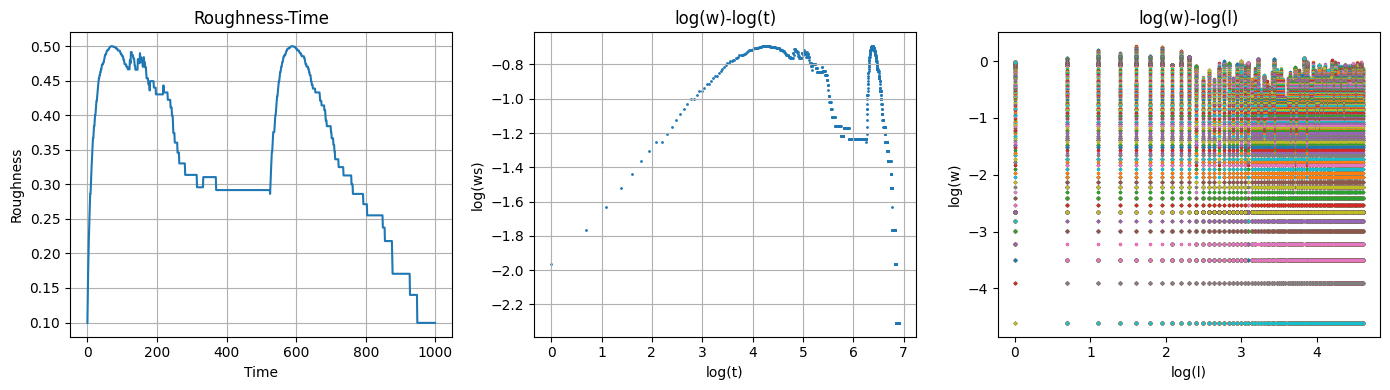

In [9]:
plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
plt.plot(time, roughness)
plt.xlabel('Time')
plt.ylabel('Roughness')
plt.grid(True)
plt.title('Roughness-Time')


plt.subplot(1, 3, 2)
log_w = np.log(roughness)
log_t = np.log(time)
plt.scatter(log_t, log_w, s=1)
plt.xlabel('log(t)')
plt.ylabel('log(ws)')
plt.grid(True)
plt.title('log(w)-log(t)')



locations = np.arange(1, size + 1)
log_l = np.log(locations)
log_w_l = []

for t in range(steps):
    mean_height = np.mean(heights[t])
    w_l = [abs(h - mean_height) for h in heights[t]]
    log_w_l.append(np.log(w_l))

plt.subplot(1, 3, 3)
for log_w in log_w_l:
    plt.scatter(log_l, log_w, s=2)
plt.xlabel('log(l)')
plt.ylabel('log(w)')
plt.title('log(w)-log(l)')

plt.tight_layout()
plt.show()

In [10]:
#x_new
log_l_new = log_l
log_t_new = log_t
#y_new
log_w_new = log_w[:len(log_l)]

coeffs_alpha = np.polyfit(log_l_new, log_w_new, 1)
alpha_1 = np.abs(coeffs_alpha[0])




log_t = np.array([0, 1, 2, 3, 4, 5, 6, 7])

period_start = 0
period_end = 4.2


condition = (log_t >= period_start) & (log_t <= period_end)
selected_log_t = log_t[condition]
log_w_new1 = log_w[:len(selected_log_t)]

coeffs_beta = np.polyfit(selected_log_t[:len(log_w_new1)], log_w_new1, 1)
beta_1 = np.abs(coeffs_beta[0])

Z = alpha_1 / beta_1

print(f"Beta : {beta_1:.4f}")
print(f"Alpha : {alpha_1:.4f}")
print(f"Z : {Z:.4f}")

Beta : 0.9190
Alpha : 0.1960
Z : 0.2133


Question 1 - Part 1.3:
Ballestic Deposition - (1D - BD By choosing the 'MAX' value compared to its neighbors)

In [11]:
size = 100  
steps = 1000  
seed = 42  

np.random.seed(seed)
surface = np.zeros(size)

heights = []
roughness = []
time = []

for t in range(steps):

    x = np.random.randint(size)

    if x == 0:
        h = 1
    else:
        h = int(np.max(surface[:x])) + 1 
    surface[x] = h

    heights.append(surface.copy())
    roughness.append(np.std(heights[-1]))
    time.append(t)

C:\Users\user\AppData\Local\Temp\ipykernel_22960\1432999023.py:12: RuntimeWarning: divide by zero encountered in log
  log_t = np.log(time)
C:\Users\user\AppData\Local\Temp\ipykernel_22960\1432999023.py:28: RuntimeWarning: divide by zero encountered in log
  log_w_l.append(np.log(w_l))


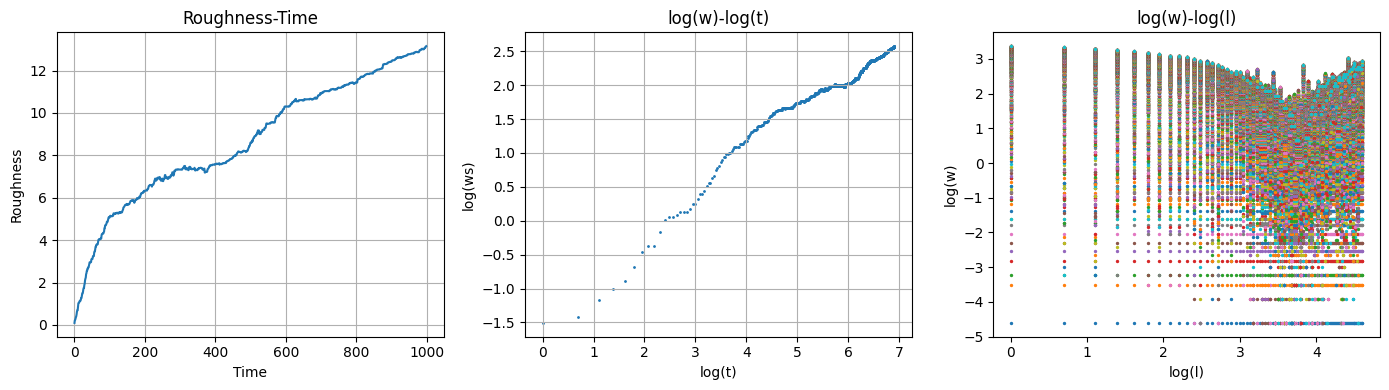

In [12]:
plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
plt.plot(time, roughness)
plt.xlabel('Time')
plt.ylabel('Roughness')
plt.grid(True)
plt.title('Roughness-Time')


plt.subplot(1, 3, 2)
log_w = np.log(roughness)
log_t = np.log(time)
plt.scatter(log_t, log_w, s=1)
plt.xlabel('log(t)')
plt.ylabel('log(ws)')
plt.grid(True)
plt.title('log(w)-log(t)')



locations = np.arange(1, size + 1)
log_l = np.log(locations)
log_w_l = []

for t in range(steps):
    mean_height = np.mean(heights[t])
    w_l = [abs(h - mean_height) for h in heights[t]]
    log_w_l.append(np.log(w_l))

plt.subplot(1, 3, 3)
for log_w in log_w_l:
    plt.scatter(log_l, log_w, s=2)
plt.xlabel('log(l)')
plt.ylabel('log(w)')
plt.title('log(w)-log(l)')

plt.tight_layout()
plt.show()

In [13]:
#x_new
log_l_new = log_l
log_t_new = log_t
#y_new
log_w_new = log_w[:len(log_l)]

coeffs_alpha = np.polyfit(log_l_new, log_w_new, 1)
alpha_2 = np.abs(coeffs_alpha[0])




log_t = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8])

period_start = 2.5
period_end = 7


condition = (log_t >= period_start) & (log_t <= period_end)
selected_log_t = log_t[condition]
log_w_new1 = log_w[:len(selected_log_t)]

coeffs_beta = np.polyfit(selected_log_t[:len(log_w_new1)], log_w_new1, 1)
beta_2 = np.abs(coeffs_beta[0])

Z = alpha_2 / beta_2

print(f"Beta : {beta_2:.4f}")
print(f"Alpha : {alpha_2:.4f}")
print(f"Z : {Z:.4f}")

Beta : 0.0372
Alpha : 0.2702
Z : 7.2685


Question 2:
Structure Function

In [14]:
def generate_surface(l):
    surface = np.zeros(l)
    for i in range(l):
        if i > 0:
            surface[i] = np.max(surface[:i]) + np.random.randint(1, 3)
    return surface

def calculate_structure_function(surface, q):
    l_values = np.arange(1, len(surface) // 2 + 1)
    structure_function = np.zeros(len(l_values))
    for i, l in enumerate(l_values):
        structure_function[i] = np.mean(np.abs(surface[l:] - surface[:-l]) ** q)
    return l_values, structure_function

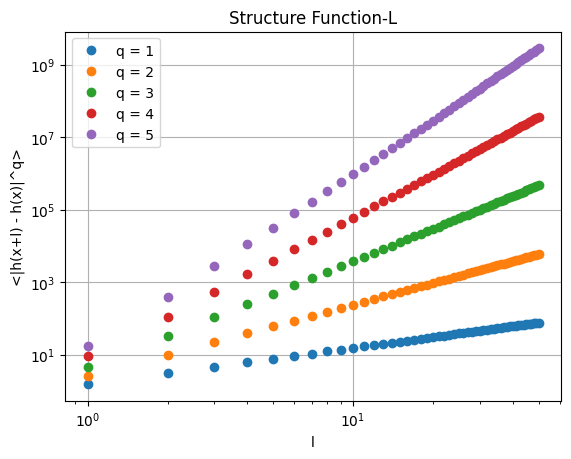

In [15]:
l = 100  
q_values = [1,2,3,4,5]  

surface = generate_surface(l)

for q in q_values:
    l_values, structure_function = calculate_structure_function(surface, q)
    plt.loglog(l_values, structure_function, 'o', label='q = {}'.format(q))

plt.xlabel('l')
plt.ylabel('<|h(x+l) - h(x)|^q>')
plt.title('Structure Function-L')
plt.legend()
plt.grid(True)
plt.show()